# 02 · Budget vs actual and revenue bridge

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohammedelsayed741996-blip/berlin-data-portfolio/blob/main/agritech-corporate-finance/month-end-close-forecast/notebooks/02_budget_vs_actual.ipynb)

Q1 of a seed company always shows a loss: costs run all year, while sugarbeet and corn seed sell in spring. So the question for September is not whether the result is negative but how far it is from plan, and why. This notebook compares actuals with budget and prior year by function, splits the revenue gap into volume and price, and explains every flagged cost line.

In [1]:
import os, sys, subprocess, warnings
from pathlib import Path

REPO = "https://github.com/mohammedelsayed741996-blip/berlin-data-portfolio.git"
PROJECT = "agritech-corporate-finance/month-end-close-forecast"

if "google.colab" in sys.modules:
    if not Path("/content/berlin-data-portfolio").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, "/content/berlin-data-portfolio"], check=True)
    os.chdir(f"/content/berlin-data-portfolio/{PROJECT}")
else:
    here = Path.cwd()
    while not (here / "src" / "close_forecast").exists() and here != here.parent:
        here = here.parent
    os.chdir(here)

sys.path.insert(0, str(Path.cwd() / "src"))
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
from IPython.display import Image, display
print("Project folder:", Path.cwd().name)

Project folder: month-end-close-forecast


In [2]:
from close_forecast import config as C, pipeline, close_checks, variance, forecast, reporting, db

tables = pipeline.load_tables()          # reads data/, or generates it if missing
run = pipeline.run(tables)
gl = tables["gl_items"]
print(f"{len(gl):,} ledger lines from {gl['month'].min()} to {gl['month'].max()}, closing {C.CLOSE_PERIOD}")

31,781 ledger lines from 2024-07 to 2026-09, closing 2026-09


## Income statement by function, July to September

Cost of sales method, group view, intercompany eliminated. Numbers are before the proposed corrections.

In [3]:
run.income_statement

,line,actual_ytd,budget_ytd,prior_year_ytd,var_vs_budget_eur
0,Revenue,"26,364,429.00","28,336,179.00","26,740,364.00","-1,971,750.00"
1,Cost of sales,"-24,542,651.00","-24,077,643.00","-22,793,893.00","-465,008.00"
2,Gross profit,"1,821,778.00","4,258,535.00","3,946,472.00","-2,436,758.00"
3,Selling,"-8,870,388.00","-9,199,174.00","-9,155,440.00","328,786.00"
4,Research and development,"-9,441,458.00","-9,355,806.00","-9,031,568.00","-85,651.00"
5,General and administration,"-3,547,446.00","-3,408,789.00","-3,260,863.00","-138,657.00"
6,Not assigned (missing cost center),"-5,600.00",0.00,0.00,"-5,600.00"
7,EBIT,"-20,043,114.00","-17,705,234.00","-17,501,399.00","-2,337,880.00"


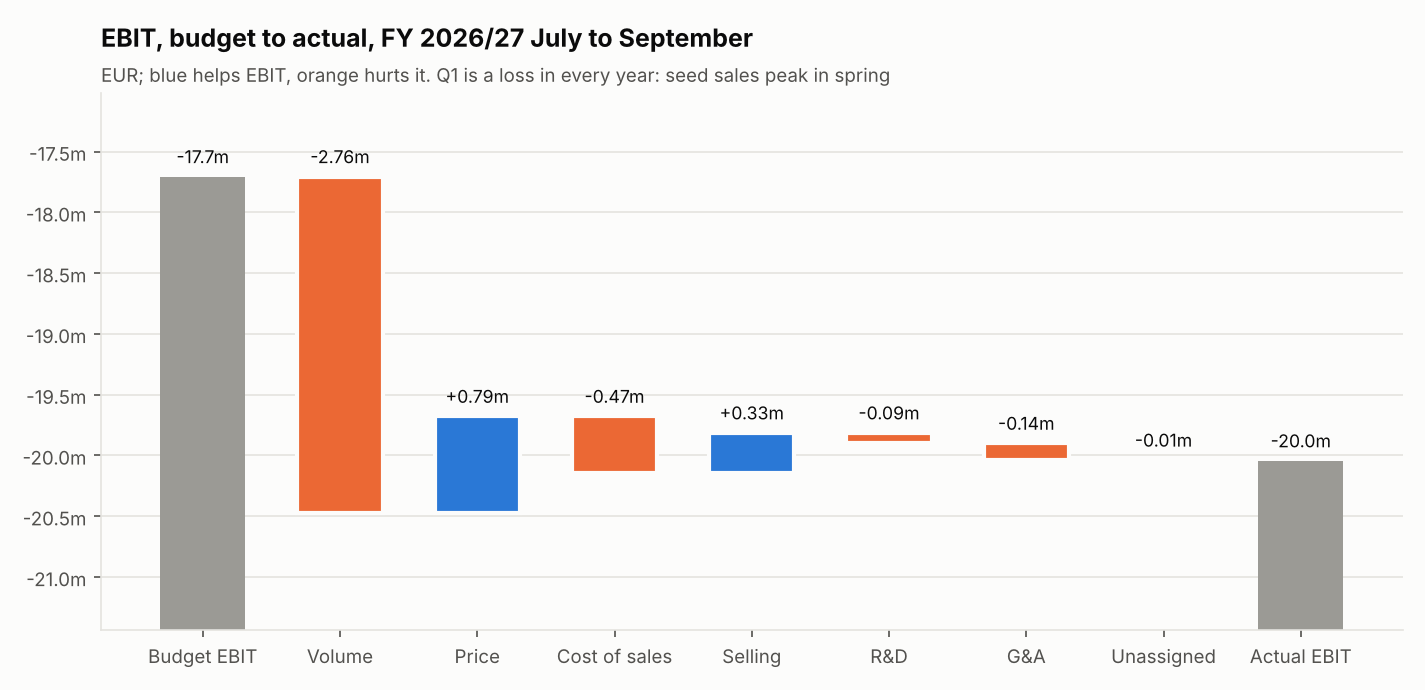

In [4]:
display(Image(filename=str(reporting.plot_ebit_bridge(reporting.ebit_bridge(run.pvm, run.income_statement), Path("outputs/figures/ebit_bridge.png")))))

## Revenue: volume and price

Volume effect is the change in units at budget price. Price effect is the change in price at actual units. Together they equal the total variance. There is no mix effect across crops, because the crops are sold in different units (seed units, decitonnes, kilograms) and a blended price per unit would mean nothing.

A dry autumn cut cereal seed volume by about 16%. The price was 4% above plan, which recovers only part of it.

,crop,units_vs_budget_pct,price_vs_budget_pct,volume_effect_eur,price_effect_eur,total_variance_eur
0,cereals,-0.15,0.05,"-2,997,750.41","812,774.77","-2,184,975.64"
1,corn,0.07,0.02,"174,286.08","55,906.82","230,192.90"
2,sugarbeet,0.01,-0.03,"30,809.58","-68,318.15","-37,508.57"
3,vegetables,0.01,-0.00,"27,999.16","-7,457.98","20,541.18"


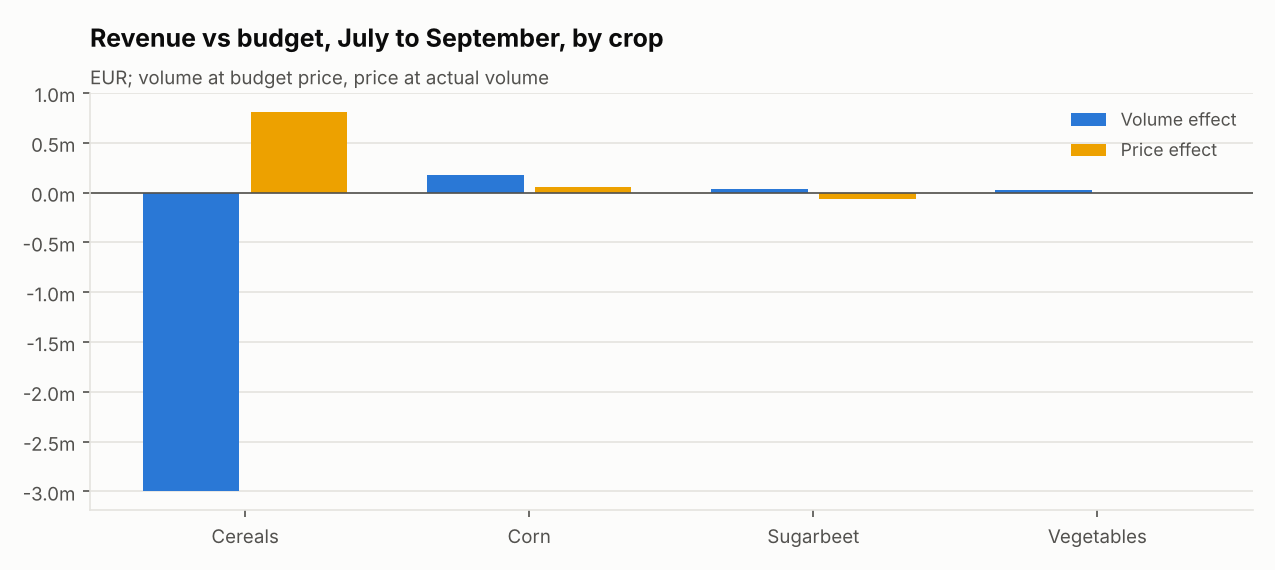

In [5]:
display(run.pvm[["crop", "units_vs_budget_pct", "price_vs_budget_pct", "volume_effect_eur", "price_effect_eur", "total_variance_eur"]])
display(Image(filename=str(reporting.plot_pvm(run.pvm, Path("outputs/figures/revenue_pvm.png")))))

## Costs by function

In [6]:
run.bva_fa[["functional_area", "actual_ytd", "budget_ytd", "var_ytd_eur", "var_ytd_pct", "prior_year_ytd", "vs_prior_year_pct"]]

,functional_area,actual_ytd,budget_ytd,var_ytd_eur,var_ytd_pct,prior_year_ytd,vs_prior_year_pct
0,,"5,600.00",0.00,"5,600.00",NaN,0.00,NaN
1,COS,"24,542,651.18","24,077,643.49","465,007.69",0.02,"22,793,892.71",0.08
2,GNA,"4,041,870.07","3,922,544.37","119,325.70",0.03,"3,762,088.21",0.07
3,RND,"9,441,457.69","9,355,806.48","85,651.21",0.01,"9,031,567.58",0.05
4,SEL,"8,870,388.39","9,199,174.12","-328,785.73",-0.04,"9,155,439.80",-0.03


At function level nothing crosses the threshold. That is the problem with function-level reporting: errors in both directions cancel out. One level down, at cost center and account, a line is flagged when the year-to-date gap is both above 10% and above EUR 25,000.

In [7]:
variance.flagged_lines(tables)[["cost_center", "cost_center_name", "account_group", "actual_ytd", "budget_ytd", "var_ytd_eur", "var_ytd_pct"]]

,cost_center,cost_center_name,account_group,actual_ytd,budget_ytd,var_ytd_eur,var_ytd_pct
0,3110,Breeding corn,External services,"542,549.59","312,413.85","230,135.74",0.74
1,2110,Sales corn DACH,External services,"612,147.74","829,541.56","-217,393.82",-0.26
2,1100,Production Einbeck,Energy,"1,164,534.28","991,288.80","173,245.48",0.17
3,1110,Seed processing,Energy,"843,928.86","703,495.27","140,433.59",0.20
4,4120,IT,External services,"459,241.90","344,184.75","115,057.15",0.33
5,1200,Production Austria,Depreciation,"195,626.38","293,439.57","-97,813.19",-0.33
6,1300,Production France,Energy,"531,572.87","479,655.87","51,917.00",0.11
7,2120,Marketing,Travel,"331,740.89","376,144.76","-44,403.87",-0.12
8,1200,Production Austria,Energy,"343,725.80","303,782.05","39,943.75",0.13
9,2300,Sales France,Rent and facilities,"71,022.24","106,533.36","-35,511.12",-0.33


## Finding a booking on the wrong cost center

Corn breeding is EUR 230k over budget on external services, and corn sales is EUR 217k under on the same account. That pattern is typical: someone booked an invoice on the wrong cost center. The function below looks for single postings that push their cost center far over its monthly budget while another cost center in the same company has the same amount unspent on the same account.

In [8]:
mis = variance.find_misallocations(tables)
display(mis.T)
variance.top_documents(tables, "3110", "6500").head(3)

,0
doc_no,1000009434
text,Corn launch campaign Q1 - agency invoice
gl_account,6500
amount_eur,"250,000.00"
booked_cost_center,3110 Breeding corn
booked_area,RND
proposed_cost_center,2110 Sales corn DACH
proposed_area,SEL
unspent_budget_there_eur,"249,729.44"


,month,doc_no,doc_type,posting_date,vendor,amount_eur,text,user_id
31779,2026-09,1000009434,KR,2026-09-22,V0212,"250,000.00",Corn launch campaign Q1 - agency invoice,U04
30997,2026-09,1000009261,KR,2026-09-28,V0123,"62,460.52",External services,U06
29833,2026-08,1000008909,KR,2026-08-18,V0241,"53,085.86",External services,U09


## Variance comments

Each flagged line gets a cause and an action, tied back to the close checks where they explain it. Two lines are left for the cost center owners, because the data alone does not explain them. A controller should say so instead of guessing.

In [9]:
run.comments[["cost_center", "cost_center_name", "account", "var_ytd_eur", "explanation", "action"]]

,cost_center,cost_center_name,account,var_ytd_eur,explanation,action
0,3110,Breeding corn,External services,"230,135.74","Document 1000009434 (Corn launch campaign Q1 - agency invoice) booked on 3110 Breeding corn, budgeted on 2...",Reclass to the budgeted cost center
1,2110,Sales corn DACH,External services,"-217,393.82","Document 1000009434 (Corn launch campaign Q1 - agency invoice) booked on 3110 Breeding corn, budgeted on 2...",Reclass to the budgeted cost center
2,1100,Production Einbeck,Energy,"173,245.48",Energy prices above the planning assumption,Forecast item; review the hedge and tariff assumptions
3,1110,Seed processing,Energy,"140,433.59",Energy prices above the planning assumption,Forecast item; review the hedge and tariff assumptions
4,4120,IT,External services,"115,057.15",Includes a duplicate vendor invoice RE-2026-08817 (check C05); the rest is cloud usage above plan,Reverse the second invoice and block the payment
5,1200,Production Austria,Depreciation,"-97,813.19",Recurring posting missing this month (check C07),Post the missing entry before the close
6,1300,Production France,Energy,"51,917.00",Energy prices above the planning assumption,Forecast item; review the hedge and tariff assumptions
7,2120,Marketing,Travel,"-44,403.87",To be explained by the cost center owner,Ask the owner
8,1200,Production Austria,Energy,"39,943.75",Energy prices above the planning assumption,Forecast item; review the hedge and tariff assumptions
9,2300,Sales France,Rent and facilities,"-35,511.12",Recurring posting missing this month (check C07),Post the missing entry before the close
